## Introduction



## Méthode points par points

![Montage](../images/figures/Figure_elec_continu-1.png)

In [1]:
#| echo: false
import numpy as np
import matplotlib.pyplot as plt

In [6]:
Ul = np.array([0,0.998,1.783,1.86,1.8995,1.919,1.94,1.958,1.974,1.989,2.003,-0.98,1.494,1.677,1.732,1.762,1.796])
Il = 1e-3*np.array([0, 0,0.19,1.08,2.02,2.96,3.91,4.86,5.81,6.76,7.71,0,0,0.01,0.05,0.12,0.27])

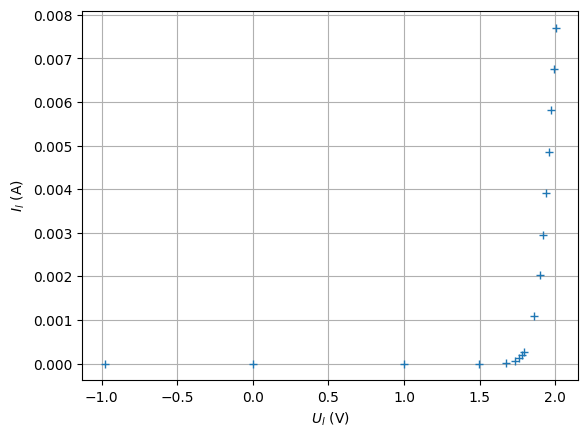

In [7]:
plt.plot( Ul, Il, '+')
plt.xlabel('$U_l$ (V)')
plt.ylabel('$I_l$ (A)')
plt.grid()

## Méthode "automatique" avec LatisPro

![Montage](../images/figures/Figure_elec_continu-2.png)

Les données sont ensuites importées en utilisant 

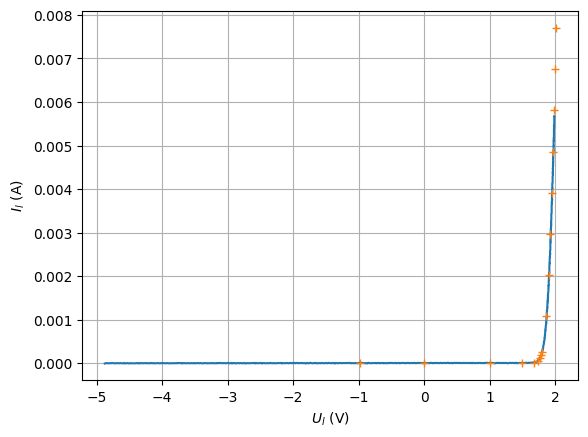

In [9]:
from importLTP import ReadLTP
import matplotlib.pyplot as plt

nom = 'Caracteristique_DEL.ltp'
data = ReadLTP( nom, info=False)

R = 1e3
Ud = data.courbe( 0 )['y'][10:]
Ur = data.courbe( 1 )['y'][10:]
I = Ur/R
plt.plot( Ud, I)

plt.plot( Ul, Il, '+')
plt.xlabel('$U_l$ (V)')
plt.ylabel('$I_l$ (A)')
plt.grid()

## Exploitation

### Equation de Shockley


Le courant $I$ qui traverse la DEL s'obtient par l'[équation de Shockley](https://fr.wikipedia.org/wiki/Diode#Caract%C3%A9ristique_r%C3%A9elle) : 
$$
    I = I_0 \left( \exp\left(
     \frac{U_d}{n*V_{\text{th}}}
    \right)
    -1
    \right)
$$
où :

- $U_d$ est la tension aux bornes de la diode;
- $V_\text{th}$ (appelé « tension thermique ») est égal à $\frac{k_\mathrm B\,T}{e}$ où $k_B$ est la constante de Boltzmann, $T$ la température absolue de la jonction et $−e$ la charge d’un électron.
- $n$ est le facteur de qualité de la diode, généralement compris entre 1 et 2;
- $I_0$ est la constante spécifique au type de diode considéré, homogène à un courant. Cette constante est aussi appelée « courant de saturation » de la diode.

[1.93639225e-14 7.50143993e-02]


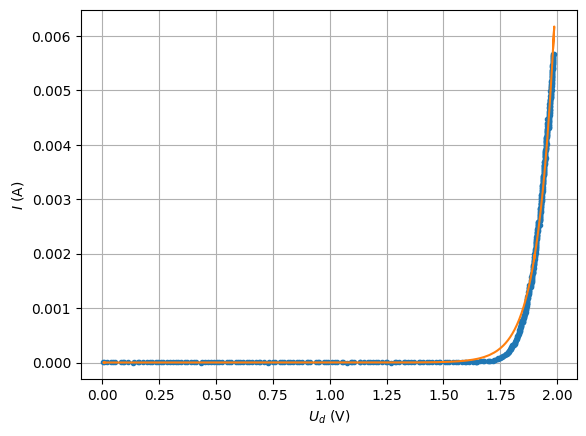

In [10]:
from scipy.optimize import curve_fit
import numpy as np
    
R = 1e3
Ud = data.courbe( 0 )['y'][10:]
Ur = data.courbe( 1 )['y'][10:]
I = Ur/R

I = I[np.where( Ud>0)]
Ud = Ud[np.where( Ud>0)]


fct = lambda x, A, Vs : A*(np.exp( x/Vs )-1)
popt, pcov = curve_fit(fct , Ud, I, p0=(1, 1) )

print( popt )

plt.plot( Ud, I, '.' )
plt.plot( Ud, fct(Ud, *popt) )

plt.ylabel('$I$ (A)')
plt.xlabel('$U_d$ (V)')
plt.grid()
plt.show()

### Tension de seuil et énergie de gap

[ 0.04510787 -0.08398033]


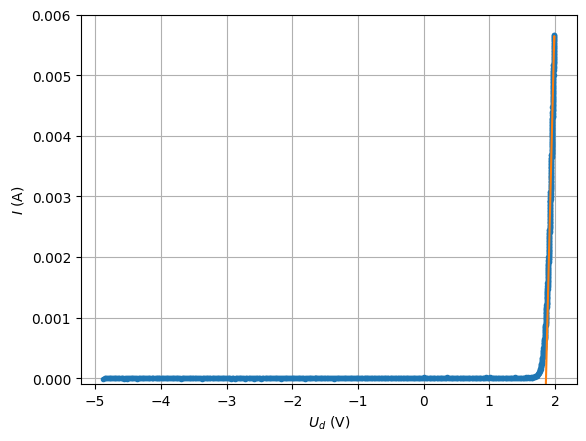

In [58]:
R = 1e3
Ud = data.courbe( 0 )['y'][10:]
Ur = data.courbe( 1 )['y'][10:]
I = Ur/R

I_c = I[np.where( Ud>1.9)]
Ud_c = Ud[np.where( Ud>1.9)]


coef = np.polyfit( Ud_c, I_c, deg=1)

print( coef )

plt.plot( Ud, I, '.' )
plt.plot( Ud, coef[0]*Ud+coef[1] )

plt.ylabel('$I$ (A)')
plt.xlabel('$U_d$ (V)')
plt.ylim(-1e-4, 6e-3)
plt.grid()
plt.show()

In [59]:
-coef[1]/coef[0]

np.float64(1.8617666792625476)